# MRP / 00 — Data checks: MNQ coverage, liquidity, gaps, exclusions, FX alignment

Protocol: [`MRP 001`](../../discussions/MNQ_Return_Prediction/001_claude_mrp01_preregistration.md). **Training window only** (2020-01-01 – 2023-06-30); nothing is selected here and no predictive relation is computed.

- Trading days, traded bars per day, days excluded (< 220 bars), gaps and contract rolls per year.
- Liquidity: minutes traded per 5-minute bar and volume, by year and session (is 2020 thick enough?).
- Targets kept after every exclusion rule (§3).
- FX coverage on the MNQ bars, and a timestamp-alignment check: contemporaneous 1-minute correlation of MNQ with EURUSD / USDJPY at offsets of −3…+3 minutes must peak at 0.

In [1]:
import json, os, sys, tempfile
import datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("MRP_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("MRP_SYNTH_DIR") or tempfile.mkdtemp(prefix="mrp_")
    os.environ["MRP_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

REPO = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(REPO / "src"))
from equity_trading import mnq_predict as P

CFG = P.SYNTH_CFG if SYNTHETIC else P.MRPConfig()
OUT = Path("00"); OUT.mkdir(exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
print("engine", P.MRP_VERSION, "| synthetic" if SYNTHETIC else "| real data", "| train", CFG.train)

if SYNTHETIC and not (Path(os.environ["EQUITY_TRADING_DIR"]) / "Databento").exists():
    P.write_synthetic(os.environ["EQUITY_TRADING_DIR"], CFG.warmup_start, CFG.test[1], CFG)


engine 0.1.0 | real data | train (datetime.date(2020, 1, 1), datetime.date(2023, 6, 30))


In [2]:
grid, fx = P.load_inputs(CFG.train[1], CFG)
g = grid[P.in_window(grid, *CFG.train)]
g = g.assign(year=pd.to_datetime(g["trade_date"]).dt.year, session=P.session_of(g.index))
print(len(g), "bars,", g["trade_date"].nunique(), "CME days")

243984 bars, 884 CME days


## 1. Days, bars, exclusions, gaps, rolls

In [3]:
days = g.groupby("trade_date").agg(year=("year", "first"), n_bars=("n_bars_day", "first"))
by_year = days.groupby("year").agg(days=("n_bars", "size"), median_bars=("n_bars", "median"),
                                   excluded_days=("n_bars", lambda s: int((s < CFG.min_day_bars).sum())))
by_year["gap_bars"] = g.groupby("year")["gap"].sum()
by_year["rolls_mid_session"] = g.groupby("year")["roll"].sum()
by_year["empty_bar_share"] = g.groupby("year")["empty"].mean().round(4)
display(by_year)
display(days[days["n_bars"] < CFG.min_day_bars])
rolls = g[g["roll"]]
display(rolls[["trade_date", "slot", "instrument_id"]])

,days,median_bars,excluded_days,gap_bars,rolls_mid_session,empty_bar_share
year,,,,,,
2020,259,273.0,2,1306,4,0.0194
2021,259,276.0,1,789,4,0.0110
2022,237,276.0,1,609,3,0.0093
2023,129,276.0,1,285,2,0.0080


,year,n_bars
trade_date,,
2020-03-16,2020,156
2020-03-18,2020,216
2021-04-02,2021,183
2022-06-01,2022,24
2023-04-07,2023,183


,trade_date,slot,instrument_id
ts,,,
2020-03-16 00:00:00+00:00,2020-03-16,24,8204.0
2020-06-17 00:00:00+00:00,2020-06-17,24,13081.0
2020-09-16 00:00:00+00:00,2020-09-16,24,17706.0
2020-12-14 00:00:00+00:00,2020-12-14,12,6227.0
2021-03-17 00:00:00+00:00,2021-03-17,24,9485.0
2021-06-14 00:00:00+00:00,2021-06-14,24,3601.0
2021-09-13 00:00:00+00:00,2021-09-13,24,1447.0
2021-12-13 00:00:00+00:00,2021-12-13,12,7575.0
2022-03-16 00:00:00+00:00,2022-03-16,24,13505.0


## 2. Liquidity by year and session

minutes_traded                      volume_per_bar                         empty_share                     
session           asia london     ny   post           asia  london       ny   post        asia london     ny   post
year                                                                                                               
2020             4.959  4.949  4.928  3.635          666.0  1187.0   4631.5  436.5       0.005  0.006  0.014  0.272
2021             5.000  4.999  4.919  4.261          546.0  1177.0   6687.5  446.5       0.000  0.000  0.016  0.148
2022             4.979  4.979  4.912  4.831          936.0  2306.0  10443.0  931.5       0.004  0.004  0.018  0.034
2023             5.000  4.998  4.890  4.806          510.0  1463.0   7556.5  749.5       0.000  0.000  0.022  0.039

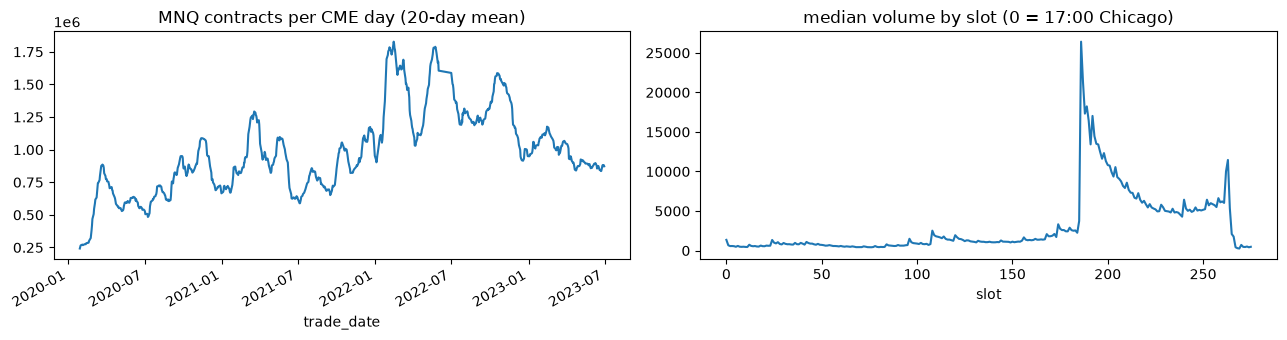

In [4]:
liq = g.groupby(["year", "session"]).agg(minutes_traded=("minutes", "mean"), volume_per_bar=("volume", "median"),
                                          empty_share=("empty", "mean")).round(3)
display(liq.unstack("session"))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
g.groupby(pd.to_datetime(g["trade_date"]))["volume"].sum().rolling(20).mean().plot(ax=ax[0], title="MNQ contracts per CME day (20-day mean)")
g.groupby("slot")["volume"].median().plot(ax=ax[1], title="median volume by slot (0 = 17:00 Chicago)")
plt.tight_layout(); plt.savefig(OUT / "liquidity.png", dpi=110); plt.show()

## 3. Targets after every rule (MRP 001 §3)

In [5]:
r = pd.DataFrame({
    "all bars": len(g),
    "minus first 3 bars of day": int((g["slot"] >= CFG.drop_first).sum()),
    "minus no return (gaps, rolls)": int(((g["slot"] >= CFG.drop_first) & g["ret"].notna()).sum()),
    "minus short days": int(((g["slot"] >= CFG.drop_first) & g["ret"].notna() & (g["n_bars_day"] >= CFG.min_day_bars)).sum()),
}, index=["bars"]).T
display(r)
zero = g.loc[(g["slot"] >= CFG.drop_first) & g["ret"].notna(), "ret"].eq(0).groupby(g["year"]).mean()
print("share of zero 5-minute returns by year (left out of the Brier score):"); display(zero.round(4))

,bars
all bars,243984
minus first 3 bars of day,241332
"minus no return (gaps, rolls)",237937
minus short days,237183


share of zero 5-minute returns by year (left out of the Brier score):


year
2020    0.0253
2021    0.0226
2022    0.0138
2023    0.0200
Name: ret, dtype: float64

## 4. FX coverage and timestamp alignment

In [6]:
cov = pd.DataFrame({p: fx[p]["ret"].reindex(g.index).notna().groupby(g["year"].to_numpy()).mean() for p in CFG.pairs}).round(4)
print("share of MNQ bars with an FX return:"); display(cov)

from equity_trading import micro_bars as MB
a, b = CFG.train[0], min(CFG.train[1], CFG.train[0] + dt.timedelta(days=182))
m1 = MB.load_1m(CFG.root, a, b)
same = m1["instrument_id"].eq(m1["instrument_id"].shift())
mr = np.log(m1["close"]).diff().where(same)
full = pd.date_range(m1.index[0], m1.index[-1], freq="1min", tz="UTC")
mr = mr.reindex(full)
rows = {}
for p in ("EURUSD", "USDJPY"):
    fm = np.log(P.load_fx_minutes(p, a - dt.timedelta(days=1), b + dt.timedelta(days=1))).reindex(full).ffill(limit=5).diff()
    rows[p] = {k: mr.corr(fm.shift(k)) for k in range(-3, 4)}
align = pd.DataFrame(rows); align.index.name = "FX shifted by (minutes; + = FX earlier)"
display(align.round(4))
print("peak offset:", {p: int(align[p].abs().idxmax()) for p in align})

share of MNQ bars with an FX return:


,EURUSD,GBPUSD,USDJPY,USDCHF,USDCAD,AUDUSD,NZDUSD
2020,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2021,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2022,1.0,1.0,1.0,1.0,1.0,1.0,1.0
2023,1.0,1.0,1.0,1.0,1.0,1.0,1.0


,EURUSD,USDJPY
FX shifted by (minutes; + = FX earlier),,
-3,0.0109,-0.0062
-2,0.0071,-0.0005
-1,0.0161,0.0014
0,0.0448,0.2791
1,0.0039,-0.0082
2,0.0048,-0.0092
3,0.0045,0.0008


peak offset: {'EURUSD': 0, 'USDJPY': 0}


In [7]:
summary = {"engine": P.MRP_VERSION, "synthetic": SYNTHETIC, "by_year": by_year.reset_index().to_dict("records"),
           "targets": r["bars"].to_dict(), "fx_coverage_min": float(cov.min().min()),
           "alignment_peak_offset": {p: int(align[p].abs().idxmax()) for p in align}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=1, default=str))
by_year.to_csv(OUT / "by_year.csv"); liq.to_csv(OUT / "liquidity.csv")